# 🗑️ Waste Level Prediction Model



Welcome to the Waste Level Prediction notebook!  
This notebook builds predictive models to forecast **waste fill levels** across bins in Zanzibar shehias,
using the collected data form the community reporting system.

## 🎯 The Goal

Predict the **Waste Level** of each bin (`Low (25%)`, `Medium (50%)`, `High (75%)`, `Full (100%)`) based on:
- Bin identity and shehia
- Time of day, day of week, week number
- Historical fill patterns

Accurate predictions help:
-  Optimize collection routes and schedules
-  Reduce unnecessary collection trips
-  Improve sanitation across 55 shehias
-  Prioritize high-activity areas

## 📚 This Notebook Covers

1. Exploratory Data Analysis (EDA) – Understanding the data
2. Data quality checks and missing value analysis
3. Feature engineering (time, bin activity)
4. Model training: **XGBoost**, **LightGBM**, **Random Forest**
5. Model comparison and best model selection
6. Predictions on the 10-day dataset

---

## 📦 Imports & Setup

This section imports all essential Python libraries for data manipulation, modelling, and visualization.

### 🔧 Libraries
- **pandas** – data loading and manipulation
- **numpy** – numerical operations
- **matplotlib / seaborn** – visualization
- **sklearn** – preprocessing, model evaluation, Random Forest
- **xgboost** – XGBoost classifier
- **lightgbm** – LightGBM classifier

### 🎨 Visualization Settings
- Uses Seaborn's `whitegrid` style for clean plots
- Sets a default figure size for consistency

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import xgboost as xgb
import lightgbm as lgb

# Visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("✓ All libraries imported successfully!")

✓ All libraries imported successfully!


## 📂 Data Loading

We load two datasets:

- **waste_10weeks_training.csv** – 10 weeks used for training (70 days × 3 readings/day)
- **waste_10days_recent.csv** – 10 most recent days used for generating predictions

Both datasets share the same columns:
`Timestamp`, `Shehia`, `Bin`, `Waste Level`, `Description`

---

In [2]:
train_df = pd.read_csv('waste_10weeks_training.csv')
test_df  = pd.read_csv('waste_10days_recent.csv')

print(f"Train dataset loaded: {train_df.shape}")
print(f"Test dataset loaded:  {test_df.shape}")

display(train_df.head())
display(test_df.head())

Train dataset loaded: (40110, 5)
Test dataset loaded:  (5730, 5)


,Timestamp,Shehia,Bin,Waste Level,Description
0,2026-01-01T07:00:47Z,Amani,AmaniA,Medium (50%),Half filled
1,2026-01-01T13:00:14Z,Amani,AmaniA,Medium (50%),Half filled
2,2026-01-01T18:00:06Z,Amani,AmaniA,High (75%),Collection recommended
3,2026-01-02T07:00:27Z,Amani,AmaniA,High (75%),Collection recommended
4,2026-01-02T13:00:05Z,Amani,AmaniA,High (75%),Needs collection


,Timestamp,Shehia,Bin,Waste Level,Description
0,2026-06-01T07:00:47Z,Amani,AmaniA,Medium (50%),Half filled
1,2026-06-01T13:00:14Z,Amani,AmaniA,Medium (50%),Half filled
2,2026-06-01T18:00:06Z,Amani,AmaniA,High (75%),Collection recommended
3,2026-06-02T07:00:27Z,Amani,AmaniA,High (75%),Collection recommended
4,2026-06-02T13:00:05Z,Amani,AmaniA,High (75%),Needs collection


## 🔍 Dataset Overview

This section confirms the structure and readiness of both datasets.

### ✅ What is checked?
- Dataset dimensions (rows × columns)
- Number of features
- Presence of the target variable (`Waste Level`) in train only

---

In [3]:
# ========================================
# 1. DATASET OVERVIEW
# ========================================

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"\nTrain Dataset Shape: {train_df.shape}")
print(f"Test Dataset Shape:  {test_df.shape}")

print(f"\nNumber of Features in Train: {train_df.shape[1]}")
print(f"Number of Features in Test:  {test_df.shape[1]}")

TARGET = 'Waste Level'
if TARGET in train_df.columns:
    print(f"\n✓ Target variable '{TARGET}' found in train set")
    print(f"✓ Target variable also present in test set (for evaluation)")
else:
    print(f"\n⚠ Target variable '{TARGET}' NOT found — check column names!")

DATASET OVERVIEW

Train Dataset Shape: (40110, 5)
Test Dataset Shape:  (5730, 5)

Number of Features in Train: 5
Number of Features in Test:  5

✓ Target variable 'Waste Level' found in train set
✓ Target variable also present in test set (for evaluation)


## 🎯 Target Variable Analysis (Waste Level)

This section explores the **target variable** to understand its distribution and check for class imbalance.

### 📊 Distribution Overview
- Count and proportion of each waste level class

### 📈 Visualizations
1. **Bar Chart** – absolute frequency of each class
2. **Pie Chart** – proportional view

### ⚖️ Class Imbalance Check
- Ratio between largest and smallest class
- Imbalance may require class weighting during training

---


TARGET VARIABLE ANALYSIS

Waste Level Distribution:
Waste Level
Low (25%)        6366
Medium (50%)    10416
High (75%)      10115
Full (100%)     13213
Name: count, dtype: int64

Waste Level Proportions:
Waste Level
Low (25%)       0.1587
Medium (50%)    0.2597
High (75%)      0.2522
Full (100%)     0.3294
Name: proportion, dtype: float64


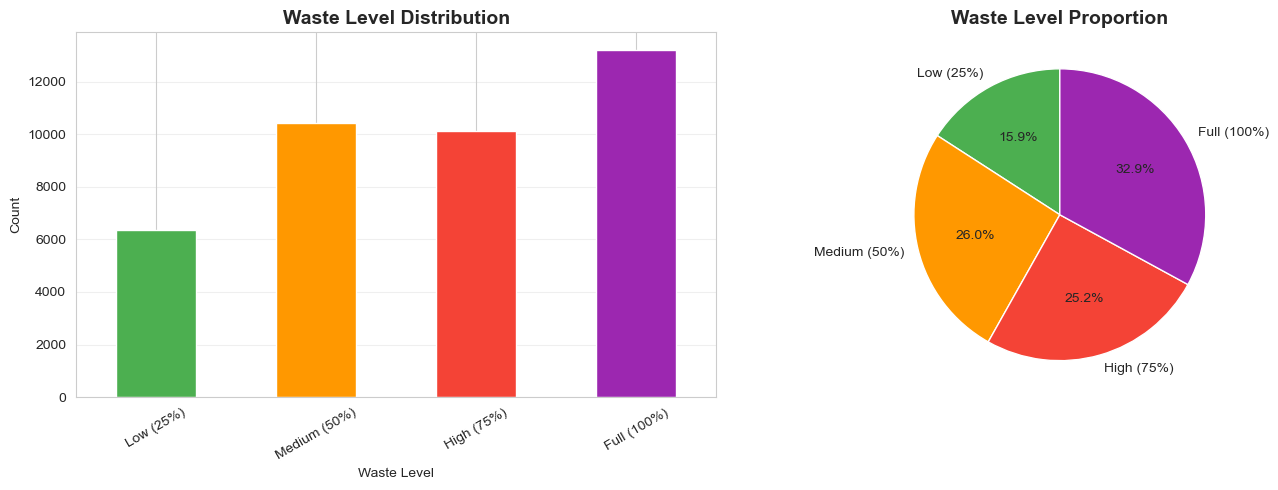


⚠ Class imbalance detected! Ratio: 2.08:1


In [4]:
# ========================================
# 2. TARGET VARIABLE ANALYSIS
# ========================================

print("\n" + "=" * 60)
print("TARGET VARIABLE ANALYSIS")
print("=" * 60)

# Enforce display order
level_order = ['Low (25%)', 'Medium (50%)', 'High (75%)', 'Full (100%)']

print("\nWaste Level Distribution:")
print(train_df[TARGET].value_counts()[level_order])

print("\nWaste Level Proportions:")
print(train_df[TARGET].value_counts(normalize=True)[level_order].round(4))

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts = train_df[TARGET].value_counts()[level_order]
colors = ['#4caf50', '#ff9800', '#f44336', '#9c27b0']

counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white')
axes[0].set_title('Waste Level Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Waste Level')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(axis='y', alpha=0.3)

axes[1].pie(counts, labels=counts.index, autopct='%1.1f%%',
            startangle=90, colors=colors)
axes[1].set_title('Waste Level Proportion', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

class_ratio = counts.max() / counts.min()
if class_ratio > 1.5:
    print(f"\n⚠ Class imbalance detected! Ratio: {class_ratio:.2f}:1")
else:
    print(f"\n✓ Classes are relatively balanced. Ratio: {class_ratio:.2f}:1")

## 🧾 Basic Dataset Information

Structural overview using `DataFrame.info()` for both datasets:
- Column names and data types
- Non-null counts (identify missing values)
- Memory usage

---

In [5]:
# ========================================
# 3. BASIC INFORMATION
# ========================================

print("\n" + "=" * 60)
print("BASIC DATASET INFORMATION")
print("=" * 60)

print("\n--- TRAIN SET INFO ---")
print(train_df.info())

print("\n--- TEST SET INFO ---")
print(test_df.info())


BASIC DATASET INFORMATION

--- TRAIN SET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40110 entries, 0 to 40109
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Timestamp    40110 non-null  object
 1   Shehia       40110 non-null  object
 2   Bin          40110 non-null  object
 3   Waste Level  40110 non-null  object
 4   Description  40110 non-null  object
dtypes: object(5)
memory usage: 1.5+ MB
None

--- TEST SET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5730 entries, 0 to 5729
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Timestamp    5730 non-null   object
 1   Shehia       5730 non-null   object
 2   Bin          5730 non-null   object
 3   Waste Level  5730 non-null   object
 4   Description  5730 non-null   object
dtypes: object(5)
memory usage: 224.0+ KB
None


## 🧩 Missing Values Analysis

Analyzes missing data patterns in both datasets.

### 🔍 What the analysis does
- Calculates missing value count and percentage per column
- Displays columns with missing data sorted by percentage
- Visualizes top columns affected

---

In [6]:
# ========================================
# 4. MISSING VALUES ANALYSIS
# ========================================

print("\n" + "=" * 60)
print("MISSING VALUES ANALYSIS")
print("=" * 60)

def analyze_missing(df, name):
    missing = df.isnull().sum()
    missing_pct = (missing / len(df)) * 100
    missing_df = pd.DataFrame({
        'Column': missing.index,
        'Missing_Count': missing.values,
        'Percentage': missing_pct.values
    }).query('Missing_Count > 0').sort_values('Percentage', ascending=False)

    print(f"\n{name} - Columns with Missing Values:")
    if len(missing_df) > 0:
        print(missing_df.to_string(index=False))
        top_missing = missing_df.head(15)
        plt.figure(figsize=(12, 6))
        plt.barh(top_missing['Column'], top_missing['Percentage'], color='coral')
        plt.xlabel('Missing Percentage (%)')
        plt.title(f'{name} - Columns with Missing Values', fontsize=14, fontweight='bold')
        plt.gca().invert_yaxis()
        plt.grid(axis='x', alpha=0.3)
        plt.tight_layout()
        plt.show()
    else:
        print("  ✓ No missing values found!")

    return missing_df

train_missing = analyze_missing(train_df, "TRAIN SET")
test_missing  = analyze_missing(test_df,  "TEST SET")


MISSING VALUES ANALYSIS

TRAIN SET - Columns with Missing Values:
  ✓ No missing values found!

TEST SET - Columns with Missing Values:
  ✓ No missing values found!


## 🔢 Numerical Features Analysis

Examines time-based numerical features derived from the `Timestamp`.

### 📊 What is examined
- Descriptive statistics (mean, std, min, max)
- Distribution visualizations (hour, day of week, week number)

---


NUMERICAL FEATURES ANALYSIS

Time-based Numerical Features: ['_hour', '_dow', '_week', '_day']

Statistical Summary (Train):
              _hour          _dow         _week          _day
count  40110.000000  40110.000000  40110.000000  40110.000000
mean      12.666667      3.000000      5.928571     13.828571
std        4.496969      2.000025      2.914637      8.660315
min        7.000000      0.000000      1.000000      1.000000
25%        7.000000      1.000000      3.000000      6.000000
50%       13.000000      3.000000      6.000000     12.500000
75%       18.000000      5.000000      8.000000     21.000000
max       18.000000      6.000000     11.000000     31.000000


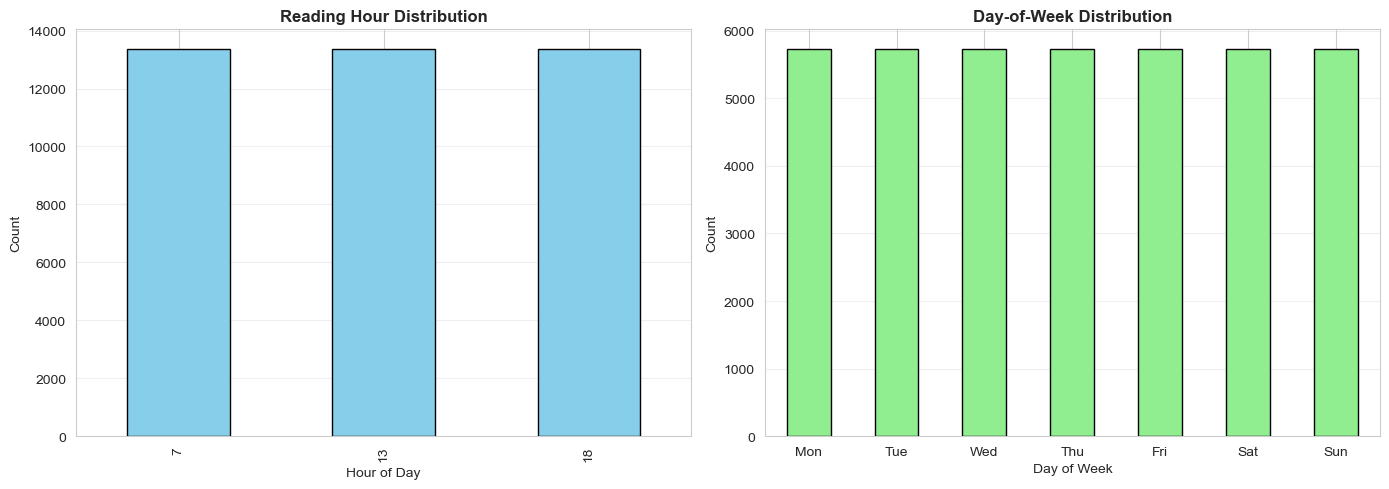

In [7]:
# ========================================
# 5. NUMERICAL FEATURES ANALYSIS
# ========================================

print("\n" + "=" * 60)
print("NUMERICAL FEATURES ANALYSIS")
print("=" * 60)

# Parse timestamp for analysis preview
train_df['Timestamp'] = pd.to_datetime(train_df['Timestamp'])
test_df['Timestamp']  = pd.to_datetime(test_df['Timestamp'])

for df, name in [(train_df, 'Train'), (test_df, 'Test')]:
    df['_hour']    = df['Timestamp'].dt.hour
    df['_dow']     = df['Timestamp'].dt.dayofweek
    df['_week']    = df['Timestamp'].dt.isocalendar().week.astype(int)
    df['_day']     = df['Timestamp'].dt.day

numerical_cols = ['_hour', '_dow', '_week', '_day']
print("\nTime-based Numerical Features:", numerical_cols)
print("\nStatistical Summary (Train):")
print(train_df[numerical_cols].describe())

# Visualize hour and day-of-week distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_df['_hour'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Reading Hour Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Count')
axes[0].grid(axis='y', alpha=0.3)

dow_labels = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
train_df['_dow'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='lightgreen', edgecolor='black')
axes[1].set_xticklabels(dow_labels, rotation=0)
axes[1].set_title('Day-of-Week Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Count')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Drop temp columns
train_df.drop(columns=['_hour','_dow','_week','_day'], inplace=True)
test_df.drop(columns=['_hour','_dow','_week','_day'], inplace=True)

## 🏷️ Categorical Features Analysis

Explores categorical variables: `Shehia`, `Bin`, `Description`.

### 🔢 Cardinality Analysis
- Number of unique values per categorical feature
- High-cardinality features may need special encoding

---

In [8]:
# ========================================
# 6. CATEGORICAL FEATURES ANALYSIS
# ========================================

print("\n" + "=" * 60)
print("CATEGORICAL FEATURES ANALYSIS")
print("=" * 60)

categorical_cols = ['Shehia', 'Bin', 'Description']
print(f"\nCategorical Features ({len(categorical_cols)}): {categorical_cols}")

print("\nCardinality (Unique Values):")
cardinality_df = pd.DataFrame({
    'Feature': categorical_cols,
    'Unique_Values': [train_df[col].nunique() for col in categorical_cols]
}).sort_values('Unique_Values', ascending=False)
print(cardinality_df.to_string(index=False))


CATEGORICAL FEATURES ANALYSIS

Categorical Features (3): ['Shehia', 'Bin', 'Description']

Cardinality (Unique Values):
    Feature  Unique_Values
        Bin            191
     Shehia             56
Description             12


## 🌍 Shehia Distribution

Analyzes how observations are distributed across shehias.

### 📊 What is checked
- Records per shehia in train and test
- Balanced representation across locations

---


SHEHIA DISTRIBUTION

Unique Shehias in Train: 56
Unique Shehias in Test:  56

Top 10 Shehias by Record Count (Train):
Shehia
Magomeni              1260
Chumbuni              1050
Jangombe              1050
Kwamtipura            1050
Kilimahewa Bondeni    1050
Migombani             1050
Mpendae                840
Masumbani              840
Matarumbeta            840
Banko                  840
Name: count, dtype: int64


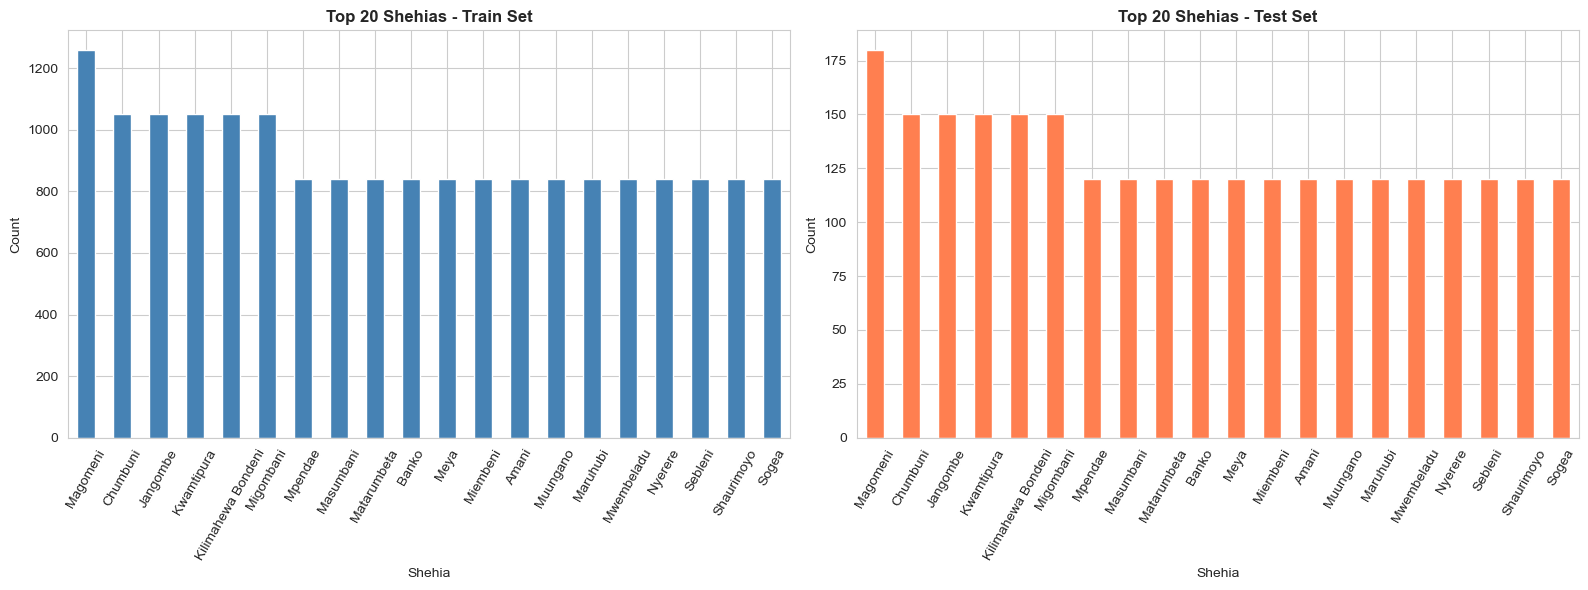

In [9]:
# ========================================
# 7. SHEHIA DISTRIBUTION
# ========================================

print("\n" + "=" * 60)
print("SHEHIA DISTRIBUTION")
print("=" * 60)

print(f"\nUnique Shehias in Train: {train_df['Shehia'].nunique()}")
print(f"Unique Shehias in Test:  {test_df['Shehia'].nunique()}")

print("\nTop 10 Shehias by Record Count (Train):")
print(train_df['Shehia'].value_counts().head(10))

# Visualize top 20 shehias
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

train_df['Shehia'].value_counts().head(20).plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Top 20 Shehias - Train Set', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Shehia')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=60)

test_df['Shehia'].value_counts().head(20).plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Top 20 Shehias - Test Set', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Shehia')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=60)

plt.tight_layout()
plt.show()

## ✅ Waste Level Patterns by Shehia & Hour

Examines how waste levels vary by shehia and time of day.

### 🔍 Patterns explored
- Full (100%) rate per shehia — identifies highest-need areas
- Waste level distribution by reading hour (morning / afternoon / evening)

---


WASTE LEVEL PATTERNS

Top 10 Shehias with Highest Full (100%) Rate:
Shehia
Mnazimmoja          0.380952
Mkunazini           0.371429
Vikokotoni          0.366667
Maruhubi            0.364286
Mchangani           0.360317
Kidongo Chekundu    0.359524
Mwembeladu          0.359524
Saateni             0.358730
Mlandege            0.357143
Malindi             0.352381
dtype: float64


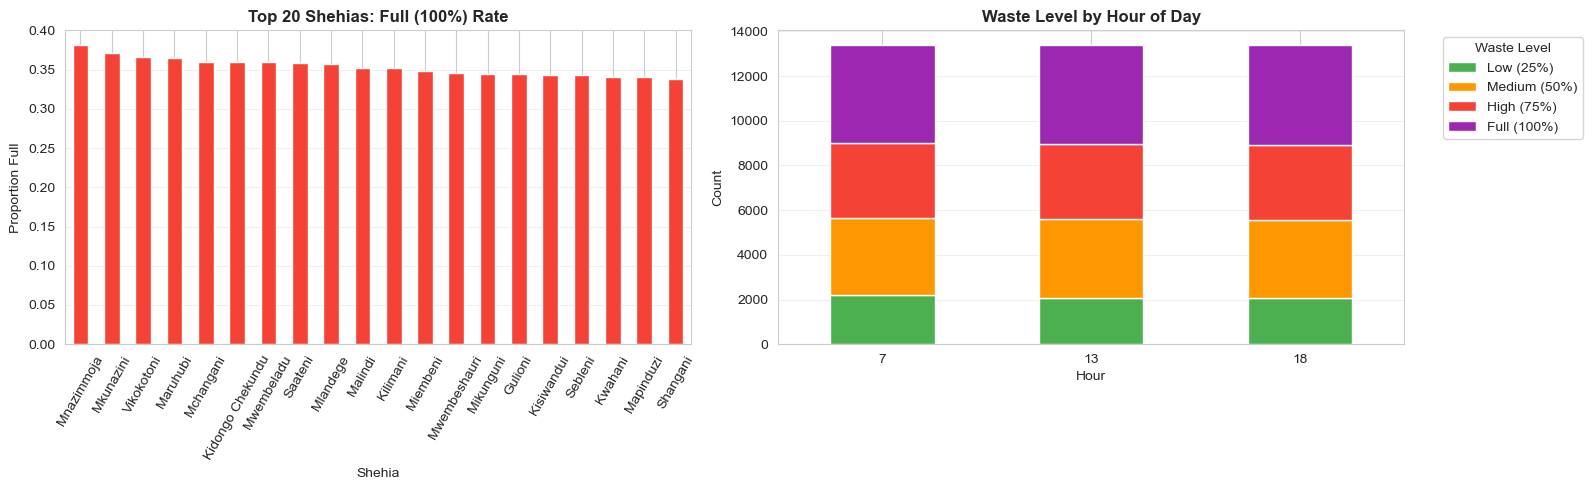

In [10]:
# ========================================
# 8. WASTE LEVEL PATTERNS
# ========================================

print("\n" + "=" * 60)
print("WASTE LEVEL PATTERNS")
print("=" * 60)

# Full (100%) rate per shehia
full_rate = (
    train_df[train_df[TARGET] == 'Full (100%)']
    .groupby('Shehia').size() / train_df.groupby('Shehia').size()
).sort_values(ascending=False)

print("\nTop 10 Shehias with Highest Full (100%) Rate:")
print(full_rate.head(10))

# Hour of day vs waste level
train_df['Hour'] = pd.to_datetime(train_df['Timestamp']).dt.hour
hour_level = train_df.groupby(['Hour', TARGET]).size().unstack(fill_value=0)
hour_level = hour_level[level_order]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

full_rate.head(20).plot(kind='bar', ax=axes[0], color='#f44336')
axes[0].set_title('Top 20 Shehias: Full (100%) Rate', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Shehia')
axes[0].set_ylabel('Proportion Full')
axes[0].tick_params(axis='x', rotation=60)
axes[0].grid(axis='y', alpha=0.3)

hour_level.plot(kind='bar', ax=axes[1], color=colors, stacked=True)
axes[1].set_title('Waste Level by Hour of Day', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hour')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Waste Level', bbox_to_anchor=(1.05, 1))
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

train_df.drop(columns=['Hour'], inplace=True)

## 🔗 Feature Relationships with Target (Waste Level)

Examines how key features relate to the waste level target.

### 🧮 Analysis
- Waste level distribution by shehia
- Waste level distribution by bin activity category

---


FEATURE RELATIONSHIPS WITH TARGET

Description vs Waste Level (cross-tab %):
Waste Level                  Full (100%)  High (75%)  Low (25%)  Medium (50%)
Description                                                                  
Almost full                          0.0       100.0        0.0           0.0
Clean                                0.0         0.0      100.0           0.0
Collection recommended               0.0       100.0        0.0           0.0
Critical                           100.0         0.0        0.0           0.0
Few wastes                           0.0         0.0      100.0           0.0
Half filled                          0.0         0.0        0.0         100.0
Immediate collection needed        100.0         0.0        0.0           0.0
Moderate waste                       0.0         0.0        0.0         100.0
Monitor                              0.0         0.0        0.0         100.0
Needs collection                     0.0       100.0        0.0 

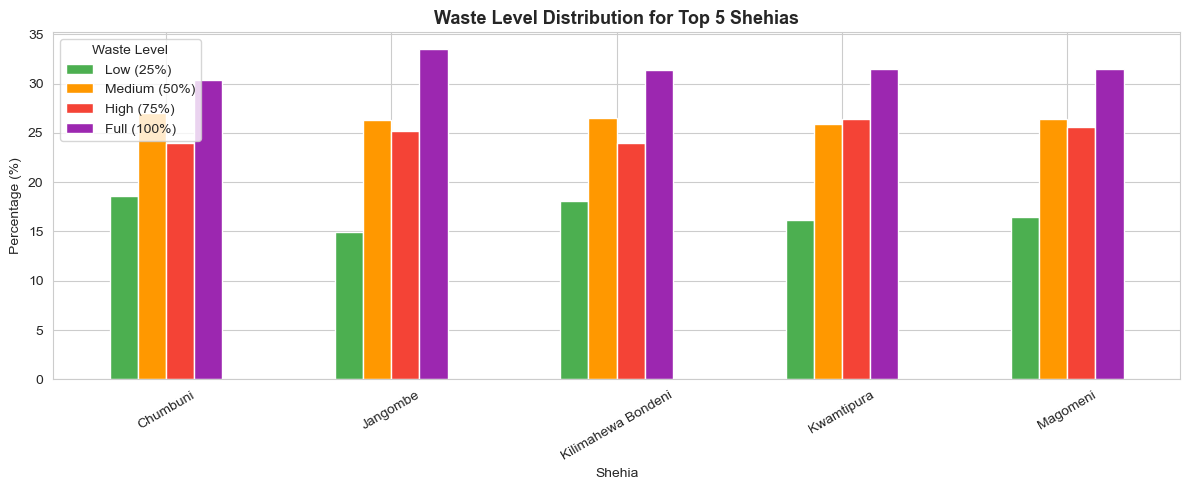

In [11]:
# ========================================
# 9. FEATURE RELATIONSHIPS WITH TARGET
# ========================================

print("\n" + "=" * 60)
print("FEATURE RELATIONSHIPS WITH TARGET")
print("=" * 60)

# Cross-tab: Description vs Waste Level
print("\nDescription vs Waste Level (cross-tab %):")
ct = pd.crosstab(train_df['Description'], train_df[TARGET], normalize='index') * 100
print(ct.round(2))

# Top shehias by waste level
print("\nWaste Level distribution for top 5 shehias:")
top5_shehia = train_df['Shehia'].value_counts().head(5).index
ct2 = pd.crosstab(train_df[train_df['Shehia'].isin(top5_shehia)]['Shehia'],
                  train_df[train_df['Shehia'].isin(top5_shehia)][TARGET],
                  normalize='index') * 100
ct2 = ct2[level_order]
print(ct2.round(2))

# Visualize
ct2.plot(kind='bar', figsize=(12, 5), color=colors)
plt.title('Waste Level Distribution for Top 5 Shehias', fontsize=13, fontweight='bold')
plt.xlabel('Shehia')
plt.ylabel('Percentage (%)')
plt.legend(title='Waste Level')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 🧪 Data Quality Checks

Key integrity checks before modeling.

### 🔹 Checks performed
- Duplicate records in train and test
- Timestamp range and coverage
- Bin consistency between train and test

---

In [12]:
# ========================================
# 10. DATA QUALITY CHECKS
# ========================================

print("\n" + "=" * 60)
print("DATA QUALITY CHECKS")
print("=" * 60)

print(f"\nDuplicate rows in Train: {train_df.duplicated().sum()}")
print(f"Duplicate rows in Test:  {test_df.duplicated().sum()}")

# Timestamp ranges
train_df['Timestamp'] = pd.to_datetime(train_df['Timestamp'])
test_df['Timestamp']  = pd.to_datetime(test_df['Timestamp'])

print(f"\nTrain date range: {train_df['Timestamp'].min().date()} → {train_df['Timestamp'].max().date()}")
print(f"Test date range:  {test_df['Timestamp'].min().date()} → {test_df['Timestamp'].max().date()}")

# Bin overlap
train_bins = set(train_df['Bin'].unique())
test_bins  = set(test_df['Bin'].unique())
missing_in_test = train_bins - test_bins
extra_in_test   = test_bins - train_bins

print(f"\nUnique bins in Train: {len(train_bins)}")
print(f"Unique bins in Test:  {len(test_bins)}")

if missing_in_test:
    print(f"⚠ Bins in Train but not in Test: {len(missing_in_test)}")
if extra_in_test:
    print(f"⚠ Bins in Test but not in Train: {len(extra_in_test)}")
if not missing_in_test and not extra_in_test:
    print("✓ Bin sets are consistent between Train and Test")

# Feature consistency
train_cols = set(train_df.columns)
test_cols  = set(test_df.columns)
if train_cols == test_cols:
    print("✓ Column sets are identical")
else:
    print(f"⚠ Column mismatch: {train_cols.symmetric_difference(test_cols)}")


DATA QUALITY CHECKS

Duplicate rows in Train: 0
Duplicate rows in Test:  0

Train date range: 2026-01-01 → 2026-03-11
Test date range:  2026-06-01 → 2026-06-10

Unique bins in Train: 191
Unique bins in Test:  191
✓ Bin sets are consistent between Train and Test
✓ Column sets are identical


## 📝 Key Insights & Recommendations

Summary of main EDA findings.

---

In [13]:
# ========================================
# 11. KEY INSIGHTS SUMMARY
# ========================================

print("\n" + "=" * 60)
print("KEY INSIGHTS & RECOMMENDATIONS")
print("=" * 60)

print("\n📊 EDA SUMMARY:")
print(f"  • Total training records:  {len(train_df):,}")
print(f"  • Total test records:      {len(test_df):,}")
print(f"  • Unique bins:             {train_df['Bin'].nunique()}")
print(f"  • Unique shehias:          {train_df['Shehia'].nunique()}")
print(f"  • Training period:         {(train_df['Timestamp'].max() - train_df['Timestamp'].min()).days} days")

if len(train_missing) > 0:
    print(f"\n⚠ Missing Data:")
    print(f"  • Features with missing values: {len(train_missing)}")
    print(f"  • Highest missing %: {train_missing['Percentage'].max():.1f}%")
else:
    print("\n✓ No missing values — clean dataset!")

print("\n💡 NEXT STEPS:")
print("  1. Engineer time features (hour, day of week, week number)")
print("  2. Encode categorical variables (Shehia, Bin → Label Encoding)")
print("  3. Map bin activity levels (High / Medium / Low)")
print("  4. Train XGBoost, LightGBM, and Random Forest")
print("  5. Compare models and select best performer")
print("  6. Generate predictions on 10-day test set")

print("\n" + "=" * 60)
print("EDA COMPLETE — Ready for Feature Engineering!")
print("=" * 60)


KEY INSIGHTS & RECOMMENDATIONS

📊 EDA SUMMARY:
  • Total training records:  40,110
  • Total test records:      5,730
  • Unique bins:             191
  • Unique shehias:          56
  • Training period:         69 days

✓ No missing values — clean dataset!

💡 NEXT STEPS:
  1. Engineer time features (hour, day of week, week number)
  2. Encode categorical variables (Shehia, Bin → Label Encoding)
  3. Map bin activity levels (High / Medium / Low)
  4. Train XGBoost, LightGBM, and Random Forest
  5. Compare models and select best performer
  6. Generate predictions on 10-day test set

EDA COMPLETE — Ready for Feature Engineering!


## 🛠️ Feature Engineering (Improved)

We create new features to significantly boost model performance.

---

### 1️⃣ Time Features
- `hour`, `day_of_week`, `week_number`, `day_of_month`, `month`, `is_weekend`, `session`

### 2️⃣ Bin Activity Level
- Static mapping: `High=2`, `Medium=1`, `Low=0`

### 3️⃣ ⭐ Bin & Shehia Target Statistics (NEW)
- `bin_mean_level`, `bin_fill_rate`, `bin_std_level` — computed from training data only
- `shehia_mean_level`, `shehia_fill_rate`

### 4️⃣ ⭐ Lag / Sequential Features (NEW — biggest accuracy gain)
- `prev_level` — previous waste level reading for the same bin
- `lag_2_level`, `lag_3_level` — two and three readings ago
- `rolling_3_mean`, `rolling_3_max` — rolling 3-reading statistics

**Why lag features?** Waste accumulation is sequential. A bin at High (75%) 5 hours ago is very
likely Full now. Without this signal the model is guessing from static metadata.

---


In [14]:
# ========================================
# 12. FEATURE ENGINEERING (IMPROVED)
# ========================================

print("\n" + "=" * 60)
print("FEATURE ENGINEERING")
print("=" * 60)

# ── Ordinal level mapping (needed for lag features) ──────────────────────────
LEVEL_ORDER  = ['Low (25%)', 'Medium (50%)', 'High (75%)', 'Full (100%)']
LEVEL_TO_INT = {v: i for i, v in enumerate(LEVEL_ORDER)}  # Low=0 … Full=3

# ── Bin activity mapping ──────────────────────────────────────────────────────
HIGH_BINS = {
    'AmaniA','BankoA','GulioniC','JangombeC','KikwajuniC','KwahaniB',
    'MalindiA','MalindiB','MalindiC','MapinduziA','MaruhubiA','MaruhubiB',
    'MchanganiA','MchanganiB','MchanganiC','MiembeniA','MikunguniC',
    'MkunaziniA','MkunaziniB','MlandegeA','MlandegeB','MnazimmojaA','MnazimmojaB',
    'MwembeladuA','MwembeladuB','RahaleoeA','SaateniA','SaateniB',
    'SebleniA','ShanganiA','VikokotoniA','VikokotoniB'
}
LOW_BINS = {
    'AmaniD','BankoC','BankoD','ChumbuniC','ChumbuniD','ChumbuniE',
    'JangombeB','KarakanaB','KikwajuniJuuB','Kilima_bondeniA','Kilima_bondeniC',
    'Kilima_bondeniD','Kilima_bondeniE','Kilima_juuC','Kilima_juuD',
    'KipondaA','KipondaB','KipondaC','KisimaA','KwaalimshaB','KwabintiamranB',
    'KwamtipuraC','KwamtipuraD','KwamtipuraE','KwamtumwajeniA','KwamtumwajeniC',
    'WazeeB','WazeeC','MagomeniC','MagomeniF','MasumbaniC','MasumbaniD',
    'MatarumbetaA','MatarumbetaB','MatarumbetaD','MboriA','MboriB','MboriC','MboriD',
    'MeyaB','MeyaD','MigombaniC','MitiB','MitiC','MkeleA','MkeleB','MkeleC',
    'MpendaeA','MuunganoB','MuunganoD','MwembeMakumbiC','MwembeMakumbiD',
    'MuembetangaB','NyerereB','NyerereC','NyerereD','SebleniC',
    'ShaurimoyoB','ShaurimoyoC','ShaurimoyoD','SogeaB','SogeaC','SogeaD',
    'UrusiA','UrusiB','UrusiC','KikwajuniJuuC'
}

def get_activity(bin_id):
    if bin_id in HIGH_BINS: return 2
    if bin_id in LOW_BINS:  return 0
    return 1

# ── Step 1: Build bin/shehia statistics FROM TRAINING DATA ONLY ──────────────
#    (avoids data leakage — test labels must never influence these stats)
TARGET = 'Waste Level'

# Sort by Bin + Timestamp before any feature engineering
train_df['Timestamp'] = pd.to_datetime(train_df['Timestamp'])
test_df['Timestamp']  = pd.to_datetime(test_df['Timestamp'])
train_df = train_df.sort_values(['Bin', 'Timestamp']).reset_index(drop=True)
train_df['is_test'] = False
test_df  = test_df.sort_values(['Bin',  'Timestamp']).reset_index(drop=True)
test_df['is_test'] = True

train_df['level_int'] = train_df[TARGET].map(LEVEL_TO_INT)

bin_stats = (train_df.groupby('Bin')['level_int']
             .agg(bin_mean_level='mean',
                  bin_fill_rate=lambda x: (x == 3).mean(),
                  bin_std_level='std')
             .reset_index())

shehia_stats = (train_df.groupby('Shehia')['level_int']
                .agg(shehia_mean_level='mean',
                     shehia_fill_rate=lambda x: (x == 3).mean())
                .reset_index())

print("✓ Bin statistics computed from training data")
print(bin_stats.describe().round(3))

# ── Step 2: Engineer features on COMBINED train+test ─────────────────────────
#    Combining ensures test rows can look back into the last training row
#    for the same bin (critical for lag features at the train/test boundary).
combined = pd.concat([train_df, test_df], sort=False).sort_values(
    ['Bin', 'Timestamp']).reset_index(drop=True)

combined['level_int'] = combined[TARGET].map(LEVEL_TO_INT)

def engineer_features(df_combined):
    df = df_combined.copy()
    ts = df['Timestamp']

    # ── Time features ─────────────────────────────────────────────────────────
    df['hour']         = ts.dt.hour
    df['day_of_week']  = ts.dt.dayofweek
    df['week_number']  = ts.dt.isocalendar().week.astype(int)
    df['day_of_month'] = ts.dt.day
    df['month']        = ts.dt.month
    df['is_weekend']   = (df['day_of_week'] >= 5).astype(int)
    df['session']      = df['hour'].map({7: 0, 13: 1, 18: 2}).fillna(1).astype(int)

    # ── Static bin activity ───────────────────────────────────────────────────
    df['bin_activity'] = df['Bin'].apply(get_activity)

    # ── Lag features (per bin, sorted by time) ───────────────────────────────
    #    These are the KEY improvement — previous reading for same bin
    df['prev_level']   = df.groupby('Bin')['level_int'].shift(1)
    df['lag_2_level']  = df.groupby('Bin')['level_int'].shift(2)
    df['lag_3_level']  = df.groupby('Bin')['level_int'].shift(3)

    # ── Rolling statistics (last 3 readings, per bin) ────────────────────────
    df['rolling_3_mean'] = (df.groupby('Bin')['level_int']
                            .transform(lambda x: x.shift(1).rolling(3, min_periods=1).mean()))
    df['rolling_3_max']  = (df.groupby('Bin')['level_int']
                            .transform(lambda x: x.shift(1).rolling(3, min_periods=1).max()))

    # ── Fill NaN lags with global median (first reading for each bin) ─────────
    for col in ['prev_level', 'lag_2_level', 'lag_3_level', 'rolling_3_mean', 'rolling_3_max']:
        df[col] = df[col].fillna(df['level_int'].median() if 'level_int' in df.columns else 1)

    return df

combined_fe = engineer_features(combined)

# ── Step 3: Merge bin/shehia stats ───────────────────────────────────────────
combined_fe = combined_fe.merge(bin_stats,    on='Bin',    how='left')
combined_fe = combined_fe.merge(shehia_stats, on='Shehia', how='left')

# Fill any bins/shehias not seen in training with global averages
for col in ['bin_mean_level', 'bin_fill_rate', 'bin_std_level',
            'shehia_mean_level', 'shehia_fill_rate']:
    combined_fe[col] = combined_fe[col].fillna(combined_fe[col].median())
train_fe  = combined_fe[combined_fe['is_test'] == False].copy()
test_fe   = combined_fe[combined_fe['is_test'] == True].copy()

print(f"\n✓ Created time features: hour, day_of_week, week_number, day_of_month, month, is_weekend, session")
print(f"✓ Created bin_activity feature (0=Low, 1=Medium, 2=High)")
print(f"✓ Created lag features: prev_level, lag_2_level, lag_3_level")
print(f"✓ Created rolling features: rolling_3_mean, rolling_3_max")
print(f"✓ Merged bin/shehia target statistics")
print(f"\n💾 Engineered datasets ready:")
print(f"   • train_fe: {train_fe.shape}")
print(f"   • test_fe:  {test_fe.shape}")



FEATURE ENGINEERING
✓ Bin statistics computed from training data
       bin_mean_level  bin_fill_rate  bin_std_level
count         191.000        191.000        191.000
mean            1.752          0.329          1.078
std             0.078          0.029          0.022
min             1.500          0.257          1.032
25%             1.690          0.310          1.062
50%             1.762          0.329          1.077
75%             1.807          0.352          1.090
max             1.914          0.390          1.148

✓ Created time features: hour, day_of_week, week_number, day_of_month, month, is_weekend, session
✓ Created bin_activity feature (0=Low, 1=Medium, 2=High)
✓ Created lag features: prev_level, lag_2_level, lag_3_level
✓ Created rolling features: rolling_3_mean, rolling_3_max
✓ Merged bin/shehia target statistics

💾 Engineered datasets ready:
   • train_fe: (40110, 25)
   • test_fe:  (5730, 25)


## 🏗️ Preparing Features and Target

Separate predictors from the target variable and encode categoricals.

### 🔹 Training Data
- **X**: All features (time + bin + shehia + activity)
- **y**: Target `Waste Level` encoded as integer

### 🔹 Test Data
- **X_test**: Same features as X

---

In [15]:
FEATURE_COLS = [
    # Time
    'hour', 'day_of_week', 'week_number', 'day_of_month', 'month',
    'is_weekend', 'session',
    # Bin identity & activity
    'bin_activity', 'bin_mean_level', 'bin_fill_rate', 'bin_std_level',
    # Shehia stats
    'shehia_mean_level', 'shehia_fill_rate',
    # ⭐ LAG FEATURES — the key improvement
    'prev_level', 'lag_2_level', 'lag_3_level',
    'rolling_3_mean', 'rolling_3_max',
    # Encoded identifiers
    'Shehia', 'Bin'
]

TARGET = 'Waste Level'

# Label-encode Shehia and Bin (fit on combined to handle all categories)
le_shehia = LabelEncoder()
le_bin    = LabelEncoder()

le_shehia.fit(pd.concat([train_fe['Shehia'], test_fe['Shehia']]))
le_bin.fit(   pd.concat([train_fe['Bin'],    test_fe['Bin']]))

train_fe['Shehia'] = le_shehia.transform(train_fe['Shehia'])
train_fe['Bin']    = le_bin.transform(train_fe['Bin'])
test_fe['Shehia']  = le_shehia.transform(test_fe['Shehia'])
test_fe['Bin']     = le_bin.transform(test_fe['Bin'])

# Label-encode target
le_target = LabelEncoder()
le_target.fit(LEVEL_ORDER)

X      = train_fe[FEATURE_COLS]
y      = le_target.transform(train_fe[TARGET])
X_test = test_fe[FEATURE_COLS]

print(f"Features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"X shape: {X.shape} | y shape: {y.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"\nTarget classes: {le_target.classes_}")


Features (20): ['hour', 'day_of_week', 'week_number', 'day_of_month', 'month', 'is_weekend', 'session', 'bin_activity', 'bin_mean_level', 'bin_fill_rate', 'bin_std_level', 'shehia_mean_level', 'shehia_fill_rate', 'prev_level', 'lag_2_level', 'lag_3_level', 'rolling_3_mean', 'rolling_3_max', 'Shehia', 'Bin']
X shape: (40110, 20) | y shape: (40110,)
X_test shape: (5730, 20)

Target classes: ['Full (100%)' 'High (75%)' 'Low (25%)' 'Medium (50%)']


## 🔀 Train-Validation Split

Split the dataset into training (80%) and validation (20%) sets.

### 🔹 How the split works
- **Stratified by target** to preserve class distribution
- **Random state = 42** for reproducibility

---

In [16]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}   | y_val:   {y_val.shape}")

print("\nClass distribution in y_train:")
unique, counts = np.unique(y_train, return_counts=True)
for u, c in zip(le_target.classes_, counts):
    print(f"  {u}: {c}")

X_train: (32088, 20) | y_train: (32088,)
X_val:   (8022, 20)   | y_val:   (8022,)

Class distribution in y_train:
  Full (100%): 10570
  High (75%): 8092
  Low (25%): 5093
  Medium (50%): 8333


## 🚀 Model 1 — XGBoost

We train an **XGBoost classifier** — a gradient boosting algorithm optimized for speed and performance.

### 🔹 Steps
1. Initialize and train the model
2. Predict on validation set
3. Evaluate: classification report + confusion matrix
4. Extract top feature importances

---

XGBoost — Classification Report:
              precision    recall  f1-score   support

 Full (100%)       0.81      0.91      0.86      2643
  High (75%)       0.83      0.83      0.83      2023
   Low (25%)       0.71      0.60      0.65      1273
Medium (50%)       0.85      0.80      0.82      2083

    accuracy                           0.81      8022
   macro avg       0.80      0.79      0.79      8022
weighted avg       0.81      0.81      0.81      8022


XGBoost — Confusion Matrix:
[[2414  148   81    0]
 [ 186 1686    0  151]
 [ 366    0  762  145]
 [   1  195  226 1661]]


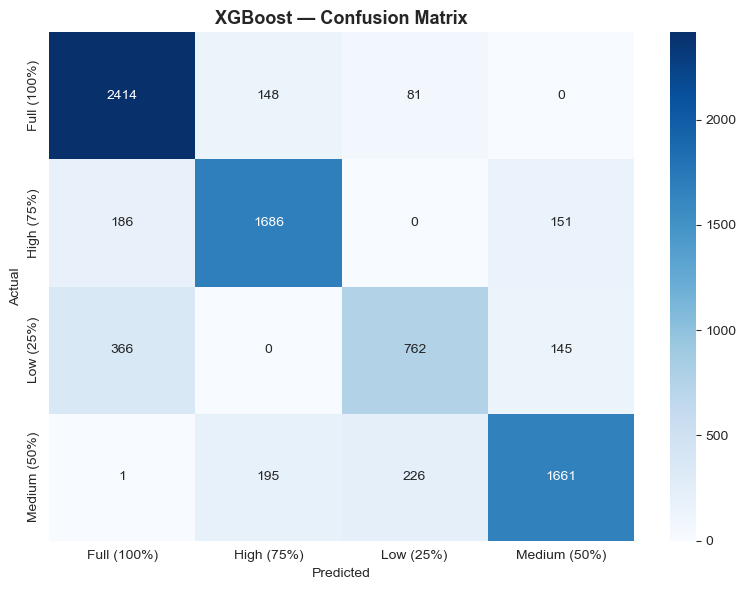


✓ XGBoost Validation Accuracy: 0.8131

XGBoost Feature Importances:
          feature  importance
    rolling_3_max    0.387967
       prev_level    0.309183
   rolling_3_mean    0.094468
      lag_3_level    0.060957
      lag_2_level    0.051395
     bin_activity    0.046877
   bin_mean_level    0.008002
    bin_fill_rate    0.004224
shehia_mean_level    0.004139
      day_of_week    0.003471
     day_of_month    0.003415
            month    0.003248
      week_number    0.003239
             hour    0.003104
    bin_std_level    0.002957
          session    0.002856
 shehia_fill_rate    0.002819
           Shehia    0.002818
              Bin    0.002680
       is_weekend    0.002183


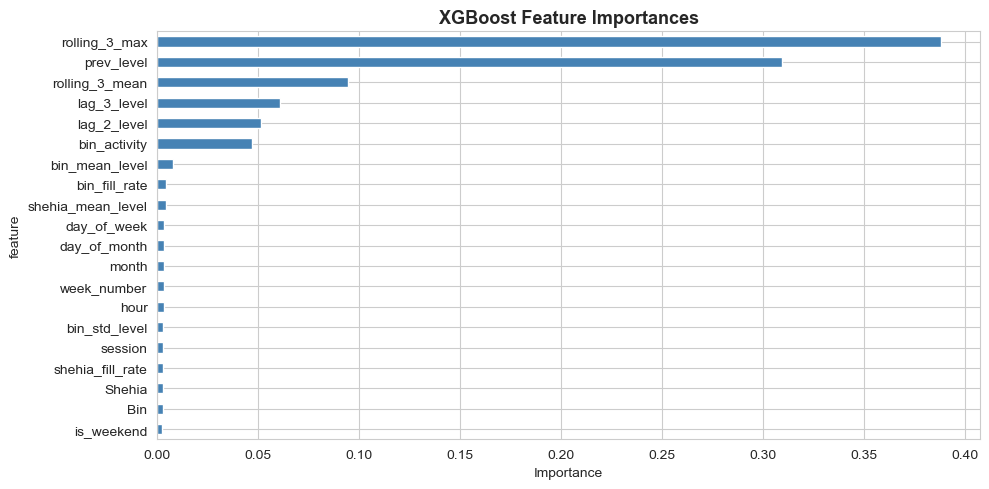

In [17]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

# -------------------------
# Train XGBoost
# -------------------------
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

# -------------------------
# Predictions
# -------------------------
xgb_pred = xgb_model.predict(X_val)

# -------------------------
# Evaluation
# -------------------------
print("XGBoost — Classification Report:")
print(classification_report(y_val, xgb_pred, target_names=le_target.classes_))

print("\nXGBoost — Confusion Matrix:")
cm_xgb = confusion_matrix(y_val, xgb_pred)
print(cm_xgb)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues',
            xticklabels=le_target.classes_, yticklabels=le_target.classes_)
plt.title('XGBoost — Confusion Matrix', fontsize=13, fontweight='bold')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

xgb_acc = accuracy_score(y_val, xgb_pred)
print(f"\n✓ XGBoost Validation Accuracy: {xgb_acc:.4f}")

# -------------------------
# Feature Importance
# -------------------------
xgb_importance = pd.DataFrame({
    'feature': FEATURE_COLS,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nXGBoost Feature Importances:")
print(xgb_importance.to_string(index=False))

xgb_importance.set_index('feature')['importance'].plot(
    kind='barh', figsize=(10, 5), color='steelblue'
)
plt.title('XGBoost Feature Importances', fontsize=13, fontweight='bold')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 🚀 Model 2 — LightGBM

We train a **LightGBM classifier** — a fast, memory-efficient gradient boosting framework.

### 🔹 Steps
1. Initialize and train LightGBM
2. Predict on validation set
3. Evaluate: classification report + confusion matrix
4. Extract feature importances

---

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007510 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 697
[LightGBM] [Info] Number of data points in the train set: 32088, number of used features: 20
[LightGBM] [Info] Start training from score -1.110462
[LightGBM] [Info] Start training from score -1.377606
[LightGBM] [Info] Start training from score -1.840615
[LightGBM] [Info] Start training from score -1.348259
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
LightGBM — Classification Report:
              precision    recall  f1-score   support

 Full (100%)       0.81      0.91      0.86      2643
  High (75%)       0.83      0.84      0.84      2023
   Low (25%)       0.71      0.60      0.65      1273
Medium (50%)       0.85      0.79      0.82      2083

    accuracy                           0

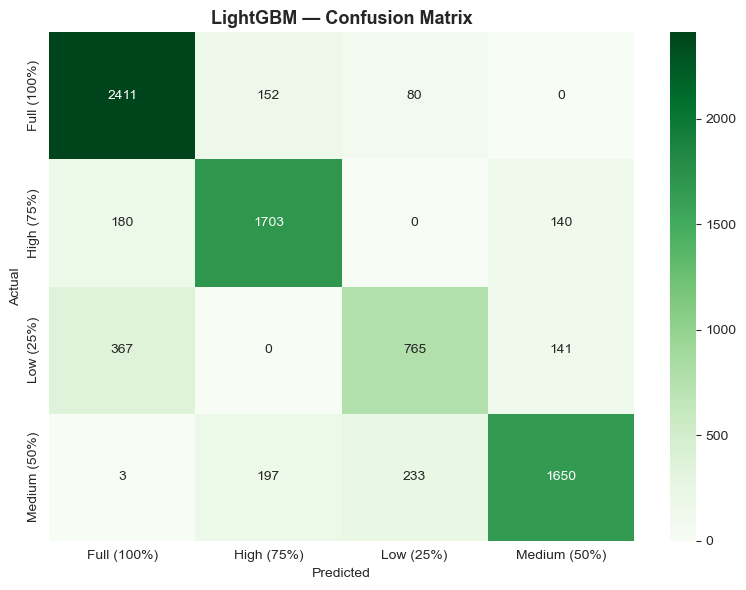


✓ LightGBM Validation Accuracy: 0.8139

LightGBM Feature Importances:
          feature  importance
     day_of_month        3638
    bin_std_level        2225
      day_of_week        1925
   bin_mean_level        1915
      week_number        1748
              Bin        1513
             hour        1457
    bin_fill_rate        1328
shehia_mean_level        1307
     bin_activity        1048
           Shehia        1011
 shehia_fill_rate         894
      lag_3_level         846
   rolling_3_mean         822
       prev_level         787
      lag_2_level         687
          session         335
            month         230
    rolling_3_max         167
       is_weekend         114


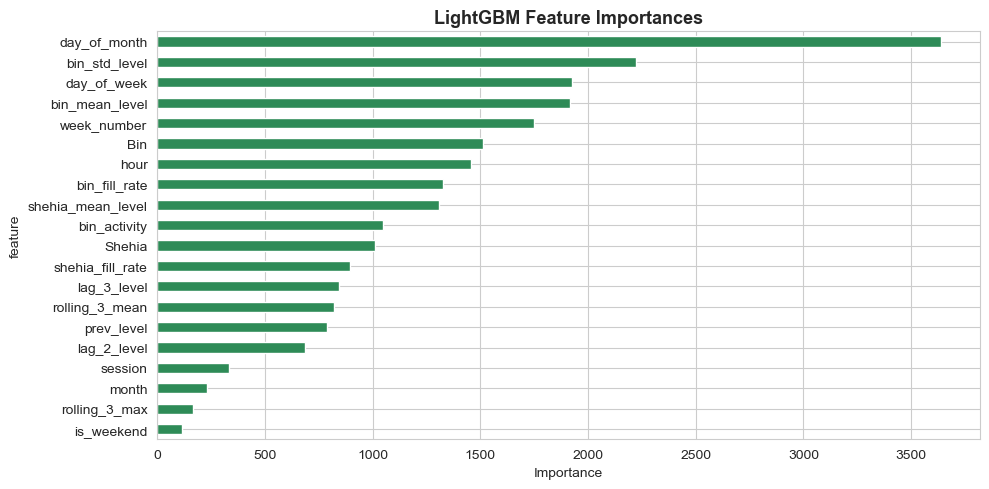

In [18]:
from lightgbm import LGBMClassifier

# -------------------------
# Train LightGBM
# -------------------------
lgbm_model = LGBMClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

lgbm_model.fit(X_train, y_train)

# -------------------------
# Predictions
# -------------------------
lgbm_pred = lgbm_model.predict(X_val)

# -------------------------
# Evaluation
# -------------------------
print("LightGBM — Classification Report:")
print(classification_report(y_val, lgbm_pred, target_names=le_target.classes_))

print("\nLightGBM — Confusion Matrix:")
cm_lgbm = confusion_matrix(y_val, lgbm_pred)
print(cm_lgbm)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_lgbm, annot=True, fmt='d', cmap='Greens',
            xticklabels=le_target.classes_, yticklabels=le_target.classes_)
plt.title('LightGBM — Confusion Matrix', fontsize=13, fontweight='bold')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

lgbm_acc = accuracy_score(y_val, lgbm_pred)
print(f"\n✓ LightGBM Validation Accuracy: {lgbm_acc:.4f}")

# -------------------------
# Feature Importance
# -------------------------
lgbm_importance = pd.DataFrame({
    'feature': FEATURE_COLS,
    'importance': lgbm_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nLightGBM Feature Importances:")
print(lgbm_importance.to_string(index=False))

lgbm_importance.set_index('feature')['importance'].plot(
    kind='barh', figsize=(10, 5), color='seagreen'
)
plt.title('LightGBM Feature Importances', fontsize=13, fontweight='bold')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 🚀 Model 3 — Random Forest

We train a **Random Forest classifier** — an ensemble of decision trees using bagging.

### 🔹 Steps
1. Initialize and train Random Forest
2. Predict on validation set
3. Evaluate: classification report + confusion matrix
4. Extract feature importances

---

Random Forest — Classification Report:
              precision    recall  f1-score   support

 Full (100%)       0.82      0.93      0.87      2643
  High (75%)       0.84      0.85      0.84      2023
   Low (25%)       0.74      0.61      0.67      1273
Medium (50%)       0.87      0.80      0.83      2083

    accuracy                           0.82      8022
   macro avg       0.82      0.80      0.80      8022
weighted avg       0.82      0.82      0.82      8022


Random Forest — Confusion Matrix:
[[2467  126   50    0]
 [ 189 1716    0  118]
 [ 368    0  775  130]
 [   1  198  227 1657]]


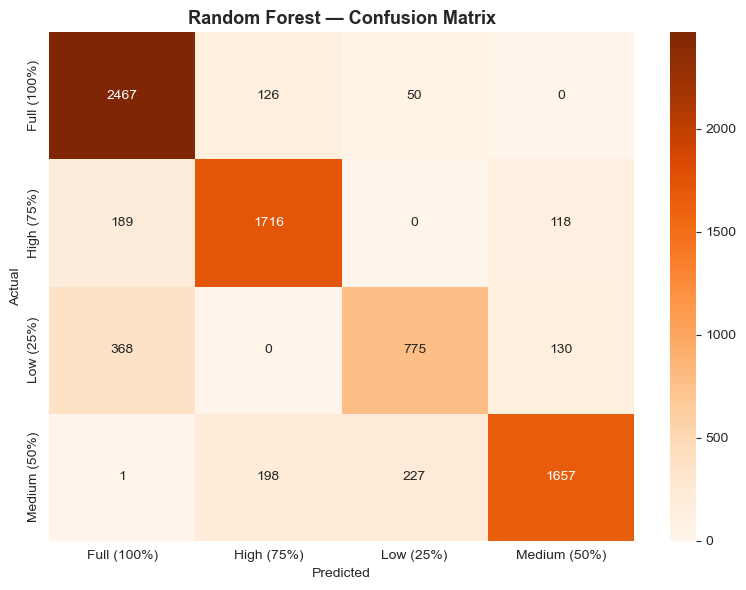


✓ Random Forest Validation Accuracy: 0.8246

Random Forest Feature Importances:
          feature  importance
       prev_level    0.251409
   rolling_3_mean    0.203193
    rolling_3_max    0.127076
      lag_2_level    0.107697
      lag_3_level    0.107313
     bin_activity    0.049344
   bin_mean_level    0.029849
    bin_fill_rate    0.018322
     day_of_month    0.016034
shehia_mean_level    0.014594
    bin_std_level    0.012682
 shehia_fill_rate    0.011684
      week_number    0.011541
      day_of_week    0.008788
              Bin    0.008228
           Shehia    0.006411
             hour    0.004665
          session    0.004489
            month    0.003505
       is_weekend    0.003176


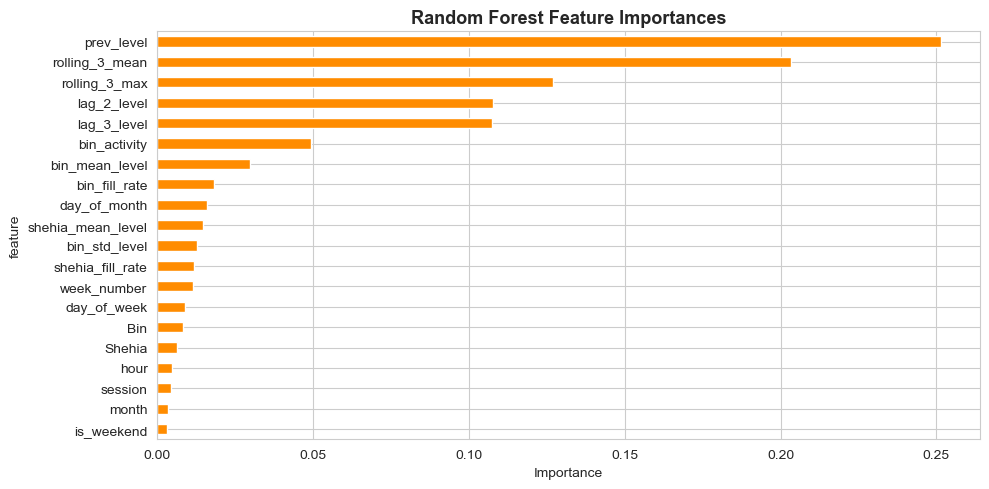

In [19]:
# -------------------------
# Train Random Forest
# -------------------------
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# -------------------------
# Predictions
# -------------------------
rf_pred = rf_model.predict(X_val)

# -------------------------
# Evaluation
# -------------------------
print("Random Forest — Classification Report:")
print(classification_report(y_val, rf_pred, target_names=le_target.classes_))

print("\nRandom Forest — Confusion Matrix:")
cm_rf = confusion_matrix(y_val, rf_pred)
print(cm_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Oranges',
            xticklabels=le_target.classes_, yticklabels=le_target.classes_)
plt.title('Random Forest — Confusion Matrix', fontsize=13, fontweight='bold')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

rf_acc = accuracy_score(y_val, rf_pred)
print(f"\n✓ Random Forest Validation Accuracy: {rf_acc:.4f}")

# -------------------------
# Feature Importance
# -------------------------
rf_importance = pd.DataFrame({
    'feature': FEATURE_COLS,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nRandom Forest Feature Importances:")
print(rf_importance.to_string(index=False))

rf_importance.set_index('feature')['importance'].plot(
    kind='barh', figsize=(10, 5), color='darkorange'
)
plt.title('Random Forest Feature Importances', fontsize=13, fontweight='bold')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 📊 Model Comparison

Compare all three models side-by-side to select the best performer.

### 🔹 Metrics compared
- Validation accuracy
- Per-class F1 scores
- Feature importance agreement across models

---


MODEL COMPARISON

Model Accuracy Comparison:
        Model  Validation Accuracy
Random Forest             0.824607
     LightGBM             0.813887
      XGBoost             0.813139


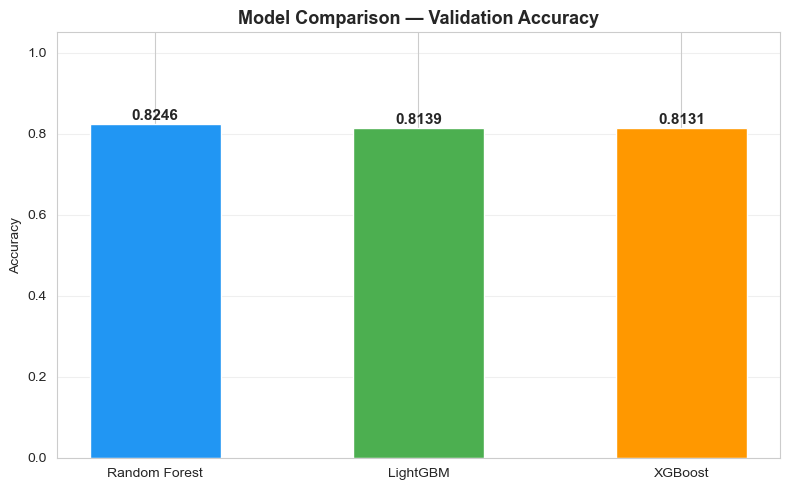


🏆 Best Model: Random Forest (Accuracy: 0.8246)


In [20]:
# ========================================
# MODEL COMPARISON
# ========================================

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

results = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM', 'Random Forest'],
    'Validation Accuracy': [xgb_acc, lgbm_acc, rf_acc]
}).sort_values('Validation Accuracy', ascending=False)

print("\nModel Accuracy Comparison:")
print(results.to_string(index=False))

# Bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(results['Model'], results['Validation Accuracy'],
               color=['#2196F3', '#4CAF50', '#FF9800'], edgecolor='white', width=0.5)
plt.title('Model Comparison — Validation Accuracy', fontsize=13, fontweight='bold')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
for bar, val in zip(bars, results['Validation Accuracy']):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

best_model_name = results.iloc[0]['Model']
best_accuracy   = results.iloc[0]['Validation Accuracy']
print(f"\n🏆 Best Model: {best_model_name} (Accuracy: {best_accuracy:.4f})")

# Select best model object
model_map = {'XGBoost': xgb_model, 'LightGBM': lgbm_model, 'Random Forest': rf_model}
best_model = model_map[best_model_name]

## 📈 Additional Evaluation Graphs (Learning Curves, ROC, Precision-Recall)

This section adds extra visualizations requested for reporting purposes:

1. **Learning Curves** — Train vs Validation performance across boosting rounds / number of trees (shows how the model learns and whether it overfits)
2. **ROC Curves** — One-vs-Rest ROC/AUC for the best model
3. **Precision-Recall Curves** — Per-class precision vs recall for the best model
4. **Train vs Validation Accuracy Comparison** — All models side-by-side

These do not change any of the original training/evaluation code above — they only add extra plots for the report.

---


### 📉 XGBoost Learning Curve (Train vs Validation)

---


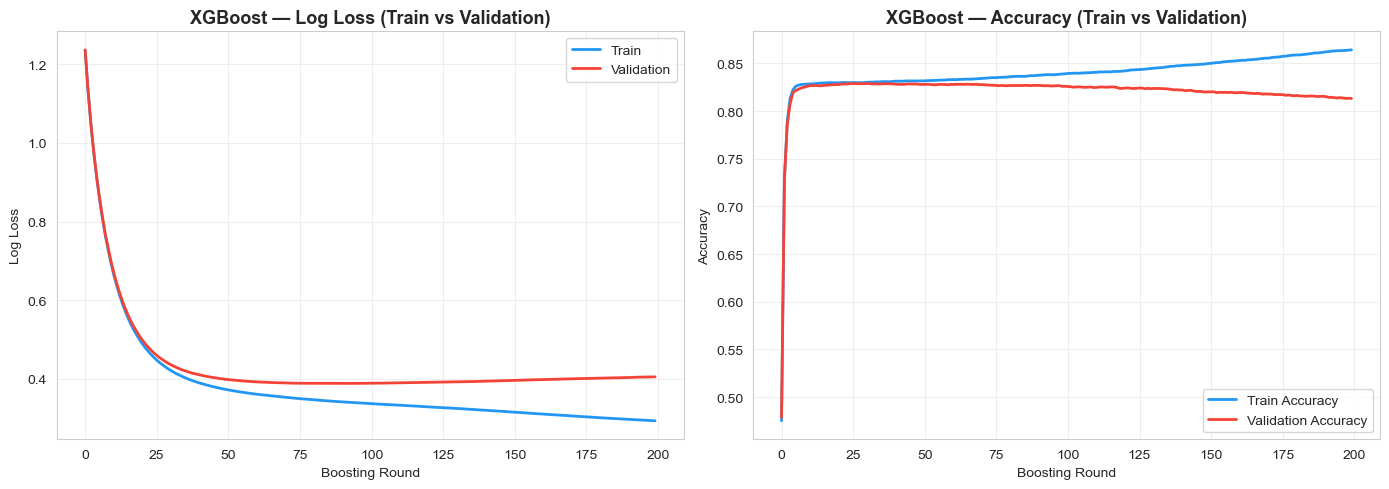

In [21]:
# ========================================
# XGBOOST LEARNING CURVE (Train vs Validation)
# ========================================
# NOTE: This retrains a copy of XGBoost with eval_set enabled purely to
# capture per-round metrics for plotting. It does not replace xgb_model above.

from xgboost import XGBClassifier

xgb_model_lc = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric=['mlogloss', 'merror'],
    random_state=42,
    n_jobs=-1
)

xgb_model_lc.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)

xgb_lc_results = xgb_model_lc.evals_result()
xgb_epochs = range(len(xgb_lc_results['validation_0']['mlogloss']))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
axes[0].plot(xgb_epochs, xgb_lc_results['validation_0']['mlogloss'], label='Train', color='#2196F3', linewidth=2)
axes[0].plot(xgb_epochs, xgb_lc_results['validation_1']['mlogloss'], label='Validation', color='#F44336', linewidth=2)
axes[0].set_title('XGBoost — Log Loss (Train vs Validation)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Boosting Round')
axes[0].set_ylabel('Log Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy curve (1 - error)
xgb_train_acc = [1 - e for e in xgb_lc_results['validation_0']['merror']]
xgb_val_acc   = [1 - e for e in xgb_lc_results['validation_1']['merror']]
axes[1].plot(xgb_epochs, xgb_train_acc, label='Train Accuracy', color='#2196F3', linewidth=2)
axes[1].plot(xgb_epochs, xgb_val_acc, label='Validation Accuracy', color='#F44336', linewidth=2)
axes[1].set_title('XGBoost — Accuracy (Train vs Validation)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Boosting Round')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 📉 LightGBM Learning Curve (Train vs Validation)

---


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001373 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 697
[LightGBM] [Info] Number of data points in the train set: 32088, number of used features: 20
[LightGBM] [Info] Start training from score -1.110462
[LightGBM] [Info] Start training from score -1.377606
[LightGBM] [Info] Start training from score -1.840615
[LightGBM] [Info] Start training from score -1.348259
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


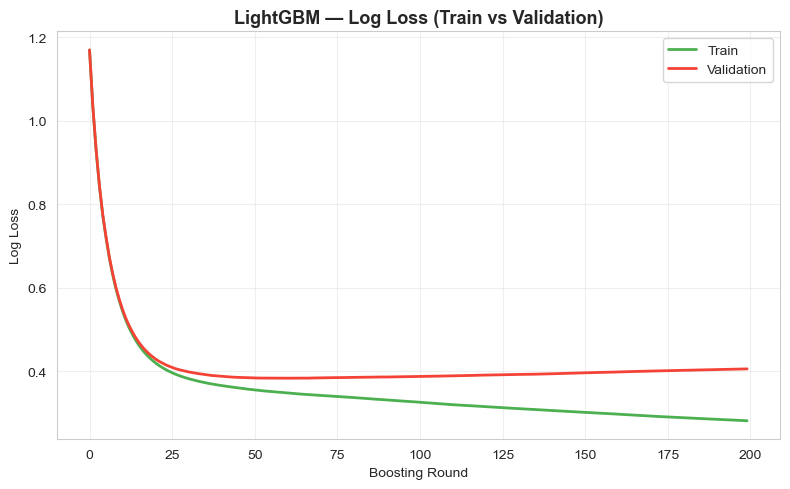

In [22]:
# ========================================
# LIGHTGBM LEARNING CURVE (Train vs Validation)
# ========================================
# NOTE: Retrains a copy of LightGBM with eval_set enabled purely to capture
# per-round metrics for plotting. Does not replace lgbm_model above.

from lightgbm import LGBMClassifier, log_evaluation

lgbm_model_lc = LGBMClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

lgbm_model_lc.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    eval_names=['Train', 'Validation'],
    eval_metric='multi_logloss',
    callbacks=[log_evaluation(period=0)]
)

lgbm_lc_results = lgbm_model_lc.evals_result_
lgbm_epochs = range(len(lgbm_lc_results['Train']['multi_logloss']))

plt.figure(figsize=(8, 5))
plt.plot(lgbm_epochs, lgbm_lc_results['Train']['multi_logloss'], label='Train', color='#4CAF50', linewidth=2)
plt.plot(lgbm_epochs, lgbm_lc_results['Validation']['multi_logloss'], label='Validation', color='#F44336', linewidth=2)
plt.title('LightGBM — Log Loss (Train vs Validation)', fontsize=13, fontweight='bold')
plt.xlabel('Boosting Round')
plt.ylabel('Log Loss')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 📉 Random Forest Learning Curve (Accuracy vs Number of Trees)

---


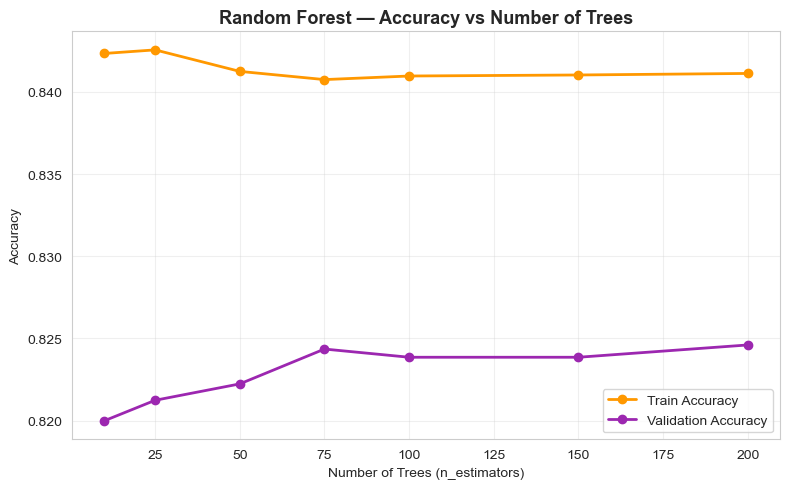

In [23]:
# ========================================
# RANDOM FOREST LEARNING CURVE (Accuracy vs Number of Trees)
# ========================================
# NOTE: Random Forest has no native eval_set, so we train several copies
# with increasing n_estimators to trace a train vs validation curve.

tree_counts = [10, 25, 50, 75, 100, 150, 200]
rf_train_accs, rf_val_accs = [], []

for n in tree_counts:
    rf_temp = RandomForestClassifier(
        n_estimators=n, max_depth=12,
        min_samples_split=5, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    )
    rf_temp.fit(X_train, y_train)
    rf_train_accs.append(accuracy_score(y_train, rf_temp.predict(X_train)))
    rf_val_accs.append(accuracy_score(y_val, rf_temp.predict(X_val)))

plt.figure(figsize=(8, 5))
plt.plot(tree_counts, rf_train_accs, marker='o', label='Train Accuracy', color='#FF9800', linewidth=2)
plt.plot(tree_counts, rf_val_accs, marker='o', label='Validation Accuracy', color='#9C27B0', linewidth=2)
plt.title('Random Forest — Accuracy vs Number of Trees', fontsize=13, fontweight='bold')
plt.xlabel('Number of Trees (n_estimators)')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 🎯 ROC Curves & Precision-Recall Curves (Best Model)

---


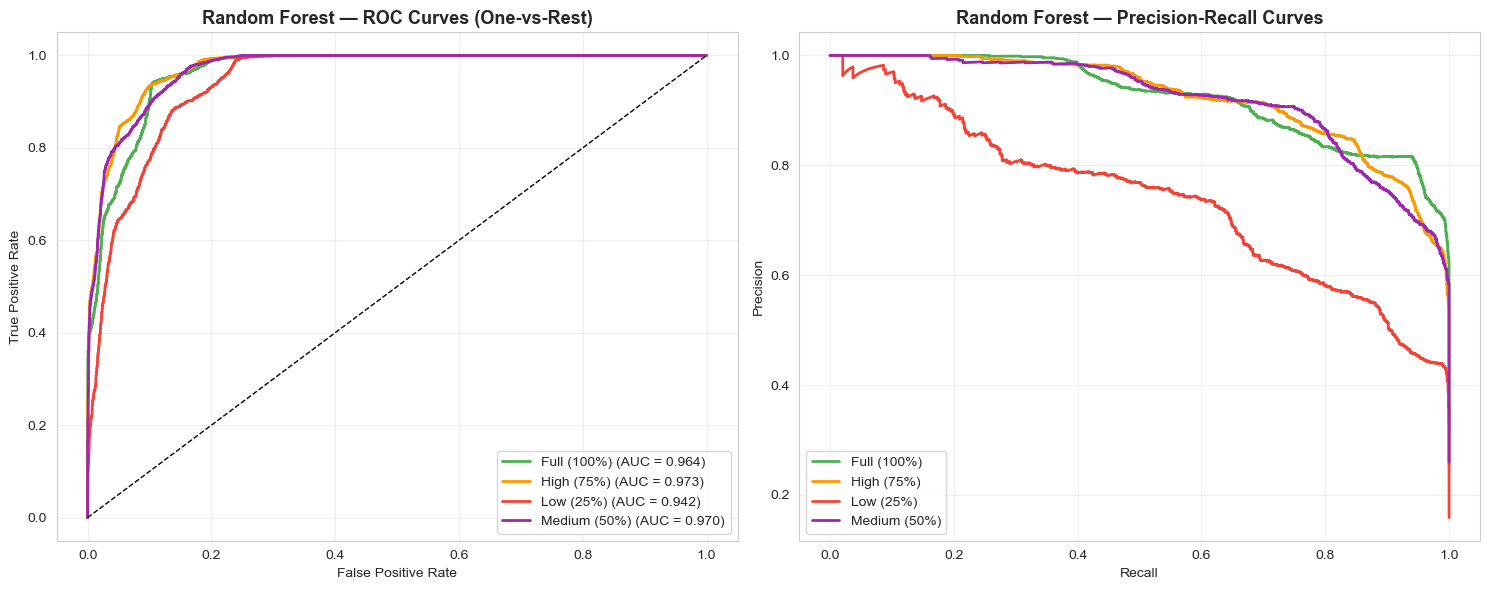

In [24]:
# ========================================
# ROC CURVES & PRECISION-RECALL CURVES (Best Model)
# ========================================
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve

y_val_bin = label_binarize(y_val, classes=[0, 1, 2, 3])
y_score = best_model.predict_proba(X_val)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
class_colors = ['#4caf50', '#ff9800', '#f44336', '#9c27b0']

# ROC curves
for i, (cls, color) in enumerate(zip(le_target.classes_, class_colors)):
    fpr, tpr, _ = roc_curve(y_val_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=color, linewidth=2, label=f'{cls} (AUC = {roc_auc:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0].set_title(f'{best_model_name} — ROC Curves (One-vs-Rest)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

# Precision-Recall curves
for i, (cls, color) in enumerate(zip(le_target.classes_, class_colors)):
    precision, recall, _ = precision_recall_curve(y_val_bin[:, i], y_score[:, i])
    axes[1].plot(recall, precision, color=color, linewidth=2, label=cls)

axes[1].set_title(f'{best_model_name} — Precision-Recall Curves', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 📊 Train vs Validation Accuracy — All Models

---


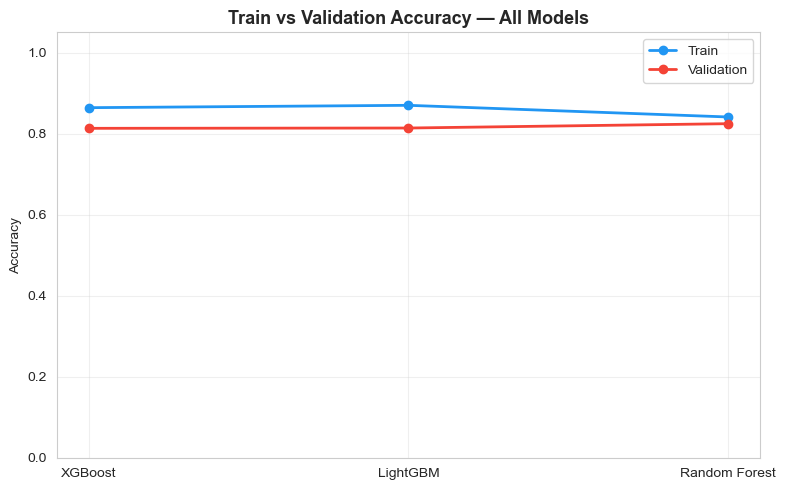


Train vs Validation Accuracy Table:
        Model  Train Accuracy  Validation Accuracy
      XGBoost        0.864092             0.813139
     LightGBM        0.869920             0.813887
Random Forest        0.841124             0.824607


In [25]:
# ========================================
# TRAIN VS VALIDATION ACCURACY - ALL MODELS
# ========================================
gap_df = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM', 'Random Forest'],
    'Train Accuracy': [
        accuracy_score(y_train, xgb_model.predict(X_train)),
        accuracy_score(y_train, lgbm_model.predict(X_train)),
        accuracy_score(y_train, rf_model.predict(X_train)),
    ],
    'Validation Accuracy': [xgb_acc, lgbm_acc, rf_acc]
})

plt.figure(figsize=(8, 5))
plt.plot(gap_df['Model'], gap_df['Train Accuracy'], marker='o', label='Train', color='#2196F3', linewidth=2)
plt.plot(gap_df['Model'], gap_df['Validation Accuracy'], marker='o', label='Validation', color='#F44336', linewidth=2)
plt.title('Train vs Validation Accuracy — All Models', fontsize=13, fontweight='bold')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTrain vs Validation Accuracy Table:")
print(gap_df.to_string(index=False))


## 📝 Generating Predictions on the 10-Day Test Set

Using the best-performing model, generate predictions on the 10-day test dataset.

### 🔹 Steps
- Predict waste levels for all bins in the test set
- Decode predictions back to human-readable labels
- Save predictions to CSV

---

In [26]:
# -------------------------
# Predict on Test Data
# -------------------------
predictions_encoded = best_model.predict(X_test)
predictions = le_target.inverse_transform(predictions_encoded)

# -------------------------
# Create Submission DataFrame
# -------------------------
pred_df = pd.DataFrame({
    'Timestamp':     test_df['Timestamp'].values,
    'Shehia':        test_fe['Shehia'].apply(lambda x: le_shehia.inverse_transform([x])[0]),
    'Bin':           test_fe['Bin'].apply(lambda x: le_bin.inverse_transform([x])[0]),
    'Actual_Level':  test_df[TARGET].values,
    'Predicted_Level': predictions
})

pred_df['Correct'] = pred_df['Actual_Level'] == pred_df['Predicted_Level']

# -------------------------
# Save to CSV
# -------------------------
pred_df.to_csv('waste_predictions.csv', index=False)
print("✓ Predictions saved to 'waste_predictions.csv'")

# -------------------------
# Preview
# -------------------------
print(f"\nTotal predictions: {len(pred_df):,}")
print(f"Overall test accuracy: {pred_df['Correct'].mean():.4f}")
display(pred_df.head(10))

✓ Predictions saved to 'waste_predictions.csv'

Total predictions: 5,730
Overall test accuracy: 0.7939


,Timestamp,Shehia,Bin,Actual_Level,Predicted_Level,Correct
210,2026-06-01 07:00:47,Amani,AmaniA,Medium (50%),Medium (50%),True
211,2026-06-01 13:00:14,Amani,AmaniA,Medium (50%),High (75%),False
212,2026-06-01 18:00:06,Amani,AmaniA,High (75%),High (75%),True
213,2026-06-02 07:00:27,Amani,AmaniA,High (75%),High (75%),True
214,2026-06-02 13:00:05,Amani,AmaniA,High (75%),Full (100%),False
215,2026-06-02 18:00:32,Amani,AmaniA,Full (100%),Full (100%),True
216,2026-06-03 07:00:12,Amani,AmaniA,Full (100%),Full (100%),True
217,2026-06-03 13:00:28,Amani,AmaniA,Full (100%),Full (100%),True
218,2026-06-03 18:00:27,Amani,AmaniA,Low (25%),Low (25%),True
219,2026-06-04 07:00:09,Amani,AmaniA,Low (25%),Medium (50%),False


## 🎉 successfully:

we have successfully:

✅ Explored and understood the  waste dataset  
✅ Engineered time-based and activity-based features  
✅ Trained **XGBoost**, **LightGBM**, and **Random Forest** classifiers  
✅ Compared models and selected the best performer  
✅ Generated predictions on the 10-day test dataset  




